# OncoPrint (Mutation Matrix)

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

A genes × samples grid in which each cell's glyph shows the type of alteration (mutation, amplification, deletion) a tumour carries in that gene. Samples are sorted so patterns of co-occurrence and mutual exclusivity stand out, and marginal bars give alteration frequencies.

## When to use

- Summarise the genomic landscape of a tumour cohort for a set of driver genes
- Show mutual exclusivity or co-occurrence of alterations across patients
- Show the alteration type and the alteration frequency in one figure

## Avoid when

- There are hundreds of genes (filter to recurrently altered or pathway genes)
- There are thousands of samples, so glyphs shrink below a pixel (aggregate or use frequency bars alone)

## Alternatives

- Stacked bar of alteration frequency per gene
- UpSet plot (exact co-occurrence counts)
- Heatmap of variant allele frequency

## Design tips

- Sort genes by alteration frequency and samples by a "memo sort" so blocks of alterations line up
- Keep the gray background cell so unaltered and missing are distinguishable
- Use full-height glyphs for copy-number changes and narrow inner bars for mutations, so both can coexist in one cell

## Example

10 cancer genes across 60 synthetic tumour samples with missense, truncating, amplification and deep-deletion events. KRAS and EGFR are simulated as mutually exclusive.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import Rectangle

### Data

In [2]:
rng = np.random.default_rng(31)
genes = ["TP53", "KRAS", "EGFR", "CDKN2A", "PIK3CA", "STK11", "KEAP1", "MYC", "BRAF", "ERBB2"]
rates = [0.50, 0.30, 0.20, 0.22, 0.15, 0.14, 0.12, 0.10, 0.06, 0.05]
types = {"TP53": ["missense", "truncating"], "KRAS": ["missense"], "EGFR": ["missense", "amplification"],
         "CDKN2A": ["deep deletion", "truncating"], "PIK3CA": ["missense", "amplification"],
         "STK11": ["truncating", "deep deletion"], "KEAP1": ["missense", "truncating"],
         "MYC": ["amplification"], "BRAF": ["missense"], "ERBB2": ["amplification", "missense"]}
n = 60
records = []
kras = rng.random(n) < 0.30
for g, r in zip(genes, rates):
    hit = rng.random(n) < r
    if g == "EGFR":
        hit = (~kras) & (rng.random(n) < 0.28)          # mutually exclusive with KRAS
    if g == "KRAS":
        hit = kras
    for s in np.where(hit)[0]:
        records.append({"sample": f"S{s:02d}", "gene": g, "alteration": rng.choice(types[g])})
alts = pd.DataFrame(records)
alts.head()

,sample,gene,alteration
0,S04,TP53,missense
1,S07,TP53,truncating
2,S09,TP53,truncating
3,S11,TP53,missense
4,S12,TP53,truncating


### Plot

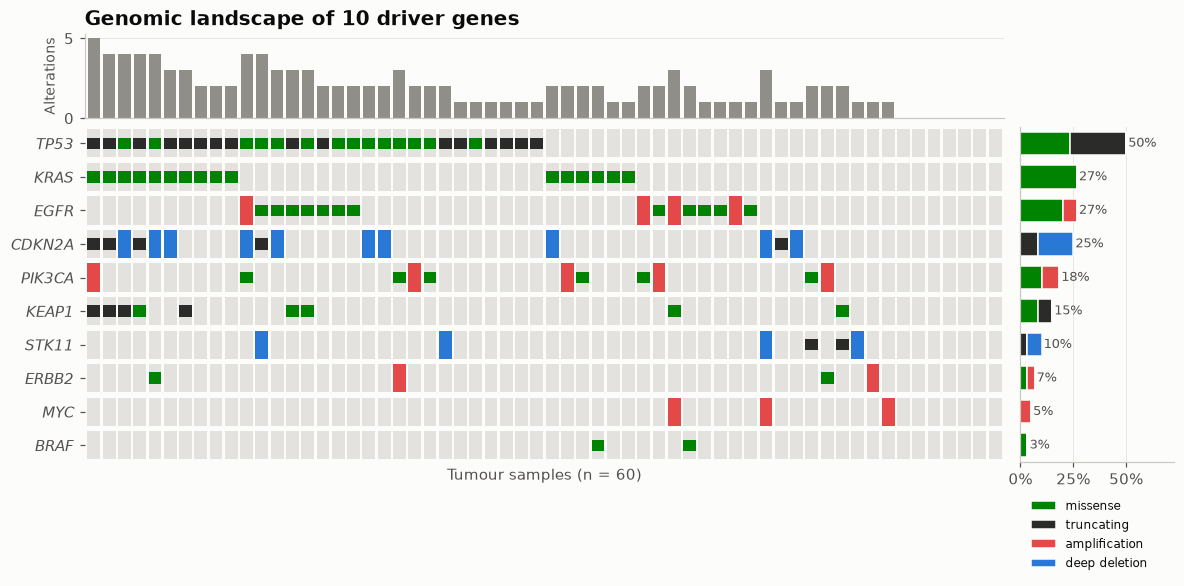

In [3]:
style = {"amplification": dict(color=PALETTE[7], full=True), "deep deletion": dict(color=PALETTE[0], full=True),
         "missense": dict(color=PALETTE[5], full=False), "truncating": dict(color="#2b2b29", full=False)}
gene_order = alts["gene"].value_counts().reindex(genes, fill_value=0).sort_values(ascending=False).index.tolist()
samples = [f"S{s:02d}" for s in range(n)]
binary = (alts.assign(v=1).pivot_table(index="gene", columns="sample", values="v", aggfunc="max")
          .reindex(index=gene_order, columns=samples).fillna(0))
sample_order = sorted(samples, key=lambda s: tuple(-binary[s].values), reverse=False)   # memo sort

fig = plt.figure(figsize=(11, 5.4))
gs = fig.add_gridspec(2, 2, width_ratios=[6, 1], height_ratios=[1, 4], wspace=0.03, hspace=0.04)
ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
gi = {g: i for i, g in enumerate(gene_order)}
si = {s: i for i, s in enumerate(sample_order)}
for g in gene_order:
    for s in sample_order:
        ax.add_patch(Rectangle((si[s] - 0.42, gi[g] - 0.42), 0.84, 0.84, color="#e3e2de", linewidth=0))
for alt_type in ["amplification", "deep deletion", "missense", "truncating"]:   # draw CNAs first
    st = style[alt_type]
    for _, r in alts[alts["alteration"] == alt_type].iterrows():
        h = 0.84 if st["full"] else 0.34
        ax.add_patch(Rectangle((si[r["sample"]] - 0.42, gi[r["gene"]] - h / 2), 0.84, h, color=st["color"], linewidth=0))
ax.set_xlim(-0.6, n - 0.4)
ax.set_ylim(len(gene_order) - 0.5, -0.5)
ax.set_yticks(range(len(gene_order)), gene_order, fontsize=10, fontstyle="italic")
ax.set_xticks([])
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlabel(f"Tumour samples (n = {n})")

per_sample = alts.groupby("sample").size().reindex(sample_order, fill_value=0)
ax_top.bar(range(n), per_sample.values, color="#8f8e88", width=0.8)
ax_top.set_ylabel("Alterations", fontsize=9)
ax_top.tick_params(axis="x", bottom=False, labelbottom=False)
ax_top.grid(axis="x", visible=False)
ax_top.set_title("Genomic landscape of 10 driver genes")

freq = (alts.groupby(["gene", "alteration"])["sample"].nunique().unstack(fill_value=0) / n)
left = np.zeros(len(gene_order))
for alt_type in ["missense", "truncating", "amplification", "deep deletion"]:
    if alt_type in freq:
        v = freq[alt_type].reindex(gene_order, fill_value=0).values
        ax_right.barh(range(len(gene_order)), v, left=left, color=style[alt_type]["color"], height=0.7,
                      edgecolor="#fcfcfb", linewidth=1, label=alt_type)
        left += v
pct = binary.mean(axis=1)
for i, p in enumerate(pct):
    ax_right.text(left[i] + 0.01, i, f"{p:.0%}", va="center", fontsize=8.5, color="#52514e")
ax_right.set_xlim(0, left.max() * 1.45)
ax_right.tick_params(axis="y", left=False, labelleft=False)
ax_right.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax_right.grid(axis="y", visible=False)
ax_right.legend(loc="upper center", bbox_to_anchor=(0.45, -0.08), fontsize=8, ncol=1)
fig.subplots_adjust(left=0.08, right=0.98, top=0.92, bottom=0.2)
plt.show()

## How to read it

Each column is one tumour and each row one gene. TP53 is altered in about half of the samples. KRAS and EGFR alterations almost never fall in the same column, which suggests mutual exclusivity. The right bars give each gene's alteration rate and the top bars give each tumour's total number of alterations.

---
Standalone script: [`oncoprint.py`](oncoprint.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)